# SymPhase tutorial 15 — quasi-harmonic and anharmonic free energies, and finite-T hulls

$$G(T,P=0)=\min_V\Big[E_\text{static}(V)+F_\text{vib}(V,T)+F_\text{anh}(V,T)\Big]$$

* $E_\text{static}$: Birch–Murnaghan EOS (fit to E–V data, or $E_0,V_0,B_0,B_0'$);
* $F_\text{vib}$: phonopy `thermal_properties.yaml` at several volumes (the phonopy-QHA workflow) **or** the Debye–Grüneisen model
  $\theta(V)=\theta_0\exp[\gamma_0(1-(V/V_0)^q)/q]$;
* $F_\text{anh}=-\tfrac32 k_B\,a\,T^2$ per atom (intrinsic anharmonicity, $a>0$ lowers $F$; $S_\text{anh}=3k_Ba T$), or a table $F_\text{anh}(T)$ from TDEP / thermodynamic integration.

Outputs: $V(T)$, volumetric $\beta=\mathrm d\ln V/\mathrm dT$ (linear $\alpha=\beta/3$), $B_T(T)$, $C_P(T)$ — and $G(T)$ for the finite-T convex hull.

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
import numpy as np, spglib, math, copy, warnings
import matplotlib.pyplot as plt
warnings.simplefilter("ignore")
from symphase import analyze_tensors
from symphase.tensors import read_poscar
from symphase.magphon import analyse_mp, bond_springs, read_magnetoelastic, plot_mp
from symphase.qha import QHA, plot_qha, EV_A3_TO_GPA
from symphase.thermo import FiniteTHull, KB
from symphase.hull import load_csv
a = 3.0
lat, fr = np.diag([a, 12, 12]), np.zeros((1, 3))
ds = spglib.get_symmetry_dataset((lat, fr, [0])); m0 = np.array([[0, 0, 2.0]])
mpdir = f"{EX}/vasp/MagnonPhonon_FM_chain"
def fm_chain(lam=6.0, dJdr=None, J=-5.0, K=0.3, n_per=120):
    me = None
    if lam:
        G = np.zeros((3, 3)); G[0, 2] = G[2, 0] = lam
        me = {(0, 0, (1, 0, 0)): [(0, G)]}
    return analyse_mp(lat, fr, [0], ["Fe"], m0, ds.rotations, ds.translations, springs=[(0, 0, [1, 0, 0], 600.0, 300.0)],
                      magnetoelastic=me, dJdr=dJdr, J=[J], K=K, K_axis=[0, 0, 1], spin=1.0, rmax=3.1, n_per=n_per)
tri = f"{EX}/vasp/Triangular_120AFM_INCAR"
def triangular(dJdr=1.5):
    t = analyze_tensors(tri, tensors="charge", ossg="no")
    p = read_poscar(f"{tri}/POSCAR"); syms = t["structure"]["symbols"]; ty = [0] * len(syms)
    d3 = spglib.get_symmetry_dataset((p["lattice"], p["frac"], ty))
    return analyse_mp(p["lattice"], p["frac"], ty, syms, np.array(t["structure"]["moments"]), d3.rotations, d3.translations,
                      springs=bond_springs(p["lattice"], p["frac"], ty, 3.6, 400.0, 150.0), dJdr=[dJdr], J=[1.0],
                      spin=1.5, rmax=3.6, n_per=40)
ni = QHA.debye_gruneisen(0.0, 10.90, 186.0, 4.6, 450.0, 1.95)          # toy fcc Ni (Debye–Grüneisen)
qcsv = f"{EX}/hull/NiAl_qha.csv"


## 1. Toy fcc Ni in the Debye–Grüneisen model ($V_0=10.9$ Å³, $B_0=186$ GPa, $\theta_0=450$ K, $\gamma_0=1.95$)

EOS: E0 = 0.00000 eV/atom, V0 = 10.9000 Å³/atom, B0 = 186.0 GPa, B0' = 4.60; F_vib: Debye–Grüneisen θ0 = 450 K, γ0 = 1.95, q = 1.00


T =   300 K  V = 11.0494 Å³  β =  38.0e-6/K  α =  12.7e-6/K  B_T =  175.5 GPa  C_P = 2.764 k_B
T =   600 K  V = 11.1873 Å³  β =  43.7e-6/K  α =  14.6e-6/K  B_T =  165.2 GPa  C_P = 3.079 k_B
T =  1000 K  V = 11.3960 Å³  β =  48.6e-6/K  α =  16.2e-6/K  B_T =  151.0 GPa  C_P = 3.270 k_B
zero-point expansion: V(0 K) = 10.9737 Å³ vs static V0 = 10.9


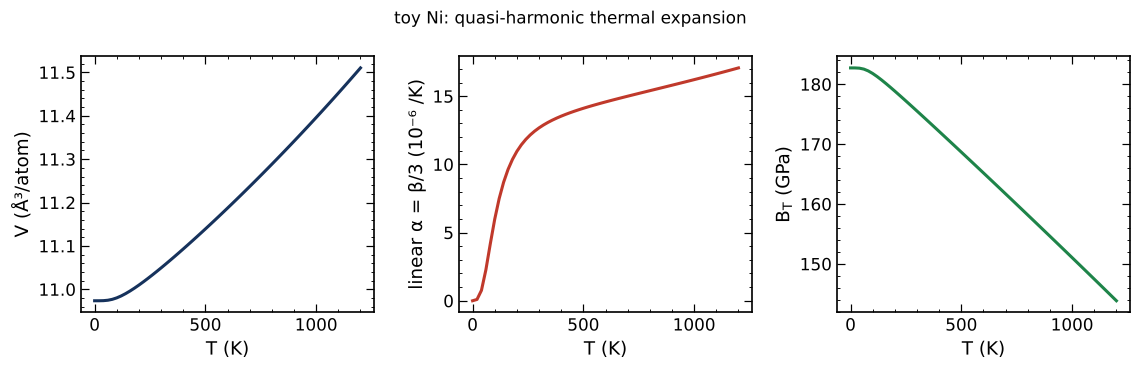

In [3]:
print(ni.summary())
plot_qha(ni, np.arange(0, 1201, 20), title="toy Ni: quasi-harmonic thermal expansion");
p = ni.properties([300, 600, 1000])
for T, V, b, al, B, cp in zip(p["T"], p["V"], p["beta"], p["alpha_lin"], p["B_T"], p["Cp"]):
    print(f"T = {T:5.0f} K  V = {V:.4f} Å³  β = {b*1e6:5.1f}e-6/K  α = {al*1e6:5.1f}e-6/K  B_T = {B:6.1f} GPa  C_P = {cp:.3f} k_B")
print("zero-point expansion: V(0 K) =", round(ni.equilibrium(0)[0], 4), "Å³ vs static V0 =", ni.V0)

**Checks.** (i) $\gamma_0=0$ ⇒ $\theta$ independent of $V$ ⇒ no thermal expansion; (ii) the Grüneisen relation $\beta B_T V=\gamma C_V$;
(iii) the anharmonic term shifts $G$ by exactly $-\tfrac32k_BaT^2$.

In [4]:
q0 = QHA.debye_gruneisen(0.0, 10.9, 186.0, 4.6, 450.0, 0.0)
print("γ = 0: V(T) =", np.round(q0.properties([10, 600, 1200])["V"], 6))
p = ni.properties([800.0]); gam = 1.95 * p["V"][0] / ni.V0
print("Grüneisen ratio βBV/(γ·3k_B) at 800 K =", round(p["beta"][0] * p["B_T"][0] / EV_A3_TO_GPA * p["V"][0] / (gam * 3 * KB), 4),
      "(→ C_V/3k_B < 1)")
qa = QHA.debye_gruneisen(0.0, 10.9, 186.0, 4.6, 450.0, 0.0, anh_a=2e-5)
print("anharmonic shift at 1000 K:", round((qa.G(1000) - q0.G(1000)) * 1e3, 6), "meV;  −3/2 k_B a T² =",
      round(-1.5 * KB * 2e-5 * 1e6 * 1e3, 6), "meV")

γ = 0: V(T) = [10.9 10.9 10.9]
Grüneisen ratio βBV/(γ·3k_B) at 800 K = 0.9864 (→ C_V/3k_B < 1)
anharmonic shift at 1000 K: -2.5852 meV;  −3/2 k_B a T² = -2.5852 meV


## 2. Phonopy workflow

Put `e-v.dat` (volume and energy per cell) and `thermal_properties-1.yaml … -N.yaml` (one phonopy run per volume) in one folder:
`QHA.from_phonopy_dir(folder, anh_a=...)`. The minimisation is identical to phonopy-qha — tested against `phonopy.PhonopyQHA`
($V$ to $2\times10^{-4}$ Å³, $G$ to $10^{-6}$ eV/atom). Here we build such a folder from the Debye–Grüneisen model and read it back:

In [5]:
import tempfile, os
from symphase.qha import birch_murnaghan, debye_theta
from symphase.thermo import debye_free_energy
tmp = tempfile.mkdtemp(); nat = 4; EVK = 96.48533212
Vs = ni.V0 * np.linspace(0.94, 1.08, 9); Ts = np.arange(0, 1201, 20.0)
with open(f"{tmp}/e-v.dat", "w") as fh:
    for V in Vs: fh.write(f"{V*nat:.8f} {birch_murnaghan(V, 0.0, ni.V0, ni.B0, ni.Bp)*nat:.10f}\n")
for k, V in enumerate(Vs):
    with open(f"{tmp}/thermal_properties-{k+1}.yaml", "w") as fh:
        fh.write(f"natom: {nat}\nthermal_properties:\n")
        for T in Ts:
            fh.write(f"- temperature: {T}\n  free_energy: {debye_free_energy(T, debye_theta(V, ni.V0, 450.0, 1.95))*nat*EVK:.10f}\n")
qp = QHA.from_phonopy_dir(tmp)
for T in (300, 900):
    print(f"T = {T} K:  V from tables {qp.equilibrium(T)[0]:.5f}   analytic model {ni.equilibrium(T)[0]:.5f}  Å³/atom")

T = 300 K:  V from tables 11.04941   analytic model 11.04941  Å³/atom
T = 900 K:  V from tables 11.34138   analytic model 11.34138  Å³/atom


## 3. Finite-temperature convex hull: harmonic → quasi-harmonic → anharmonic

`examples/hull/NiAl_qha.csv` (toy data) adds `volume, bulk_modulus, bulk_modulus_prime, gruneisen` and `anh_a` columns. The metastable
polymorph Ni₃Al-D0₁₉ has a slightly lower θ_D, a **larger Grüneisen parameter** and some intrinsic anharmonicity — it softens more on heating.

harmonic Debye      T* =  1392.7 K


quasi-harmonic      T* =   742.3 K


QHA + anharmonic    T* =   666.9 K


(-0.5, 11.073116262638782)

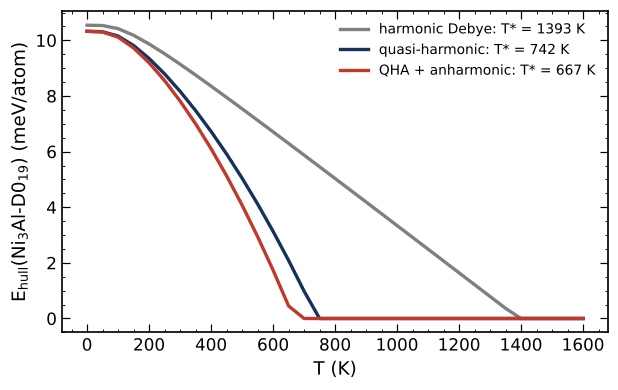

In [6]:
ents = load_csv(qcsv)
noanh = copy.deepcopy(ents)
for e in noanh: e.data.pop("anh_a", None)
models = [("harmonic Debye", noanh, "debye"), ("quasi-harmonic", noanh, "qha-debye"), ("QHA + anharmonic", ents, "qha-debye")]
Tg = np.arange(0, 1601, 50)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for (lab, E, vib), c in zip(models, ["0.5", "#16325c", "#c0392b"]):
    ft = FiniteTHull(E, vib=vib, mixing=False)
    eh = [{r_["name"]: r_["e_hull"] for r_ in ft.hull_at(T).table()}["Ni3Al-D019"] * 1e3 for T in Tg]
    Ts = ft.stabilisation_temperature("Ni3Al-D019", Tmax=3000)
    ax.plot(Tg, eh, lw=2.2, color=c, label=f"{lab}: T* = {Ts:.0f} K")
    print(f"{lab:18s}  T* = {Ts:7.1f} K")
ax.set_xlabel("T (K)"); ax.set_ylabel("E$_{hull}$(Ni$_3$Al-D0$_{19}$) (meV/atom)"); ax.legend(fontsize=9); ax.set_ylim(bottom=-0.5)

Volume-dependent phonons (QHA) almost halve the transition temperature here; intrinsic anharmonicity lowers it further.

## 4. Command line
```bash
symphase hull --csv examples/hull/NiAl_qha.csv --temperatures 0 600 1200 --vib qha-debye --no-mixing
symphase hull --csv my.csv --temperatures 300 900 --vib qha        # CSV column qha = folder with e-v.dat + thermal_properties-*.yaml
symphase run Ni Al temperatures="300 900" vib=qha-debye             # elements-only workflow (with the extra CSV columns)
```
Continue with **16_quiz_ossg_magnon_phonon_qha.ipynb**.